# Import library

In [ ]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan grafik
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Upload file CSV
from google.colab import files
uploaded = files.upload()

# Baca data
df = pd.read_csv("Data_Neraca_Beras_Bojonegoro_2021_2023.csv", sep=None, engine="python")

# Lihat bentuk dan isi awal data
print("Ukuran data:", df.shape)
df.head(10)

Saving Data_Neraca_Beras_Bojonegoro_2021_2023.csv to Data_Neraca_Beras_Bojonegoro_2021_2023.csv
Ukuran data: (36, 9)


,Tahun,Bulan,Bulan_No,Luas_Panen_Ha,Produksi_Gabah_Ton,Produksi_Beras_Ton,Konsumsi_Beras_Ton,Surplus_Defisit_Ton,Status
0,2021,Januari,1,"3,562","18,919","10,924","11,303",-379,Defisit
1,2021,Februari,2,"10,664","56,637","32,704","11,305","21,399",Surplus
2,2021,Maret,3,"41,759","221,428","127,857","11,307","116,550",Surplus
3,2021,April,4,"14,424","75,747","43,738","11,308","32,430",Surplus
4,2021,Mei,5,"5,486","24,344","14,057","11,310","2,747",Surplus
5,2021,Juni,6,"22,713","100,863","58,240","11,312","46,928",Surplus
6,2021,Juli,7,"16,078","71,378","41,215","11,314","29,901",Surplus
7,2021,Agustus,8,"1,650","7,328","4,231","11,315","-7,084",Defisit
8,2021,September,9,"3,910","20,833","12,030","11,317",713,Surplus
9,2021,Oktober,10,"6,580","35,056","20,242","11,319","8,923",Surplus


# Cek dan rapikan data

In [ ]:
nama_file = "Data_Neraca_Beras_Bojonegoro_2021_2023.csv"

# 1. Baca ulang semua sel sebagai teks
raw = pd.read_csv(nama_file, sep=None, engine="python", dtype=str, header=None)

# 2. Cari baris yang berisi judul kolom "Tahun"
#    (berjaga-jaga kalau judul tabel ikut terbawa di baris atas)
baris_header = raw.index[raw.apply(lambda r: r.str.strip().eq("Tahun").any(), axis=1)][0]
df = raw.iloc[baris_header + 1:].copy()
df.columns = raw.iloc[baris_header].str.strip()

# 3. Ambil hanya baris data (kolom Tahun berisi 4 digit angka)
df = df[df["Tahun"].str.strip().str.fullmatch(r"\d{4}", na=False)].copy()

# 4. Tambahkan nomor bulan kalau belum ada
urutan_bulan = ["Januari","Februari","Maret","April","Mei","Juni","Juli",
                "Agustus","September","Oktober","November","Desember"]
df["Bulan"] = df["Bulan"].str.strip()
if "Bulan_No" not in df.columns:
    df["Bulan_No"] = df["Bulan"].map({b: i+1 for i, b in enumerate(urutan_bulan)})

# 5. Ubah kolom angka: hapus titik/koma ribuan, lalu jadikan integer
kolom_angka = ["Luas_Panen_Ha", "Produksi_Gabah_Ton", "Produksi_Beras_Ton", "Konsumsi_Beras_Ton"]
for k in ["Tahun", "Bulan_No"] + kolom_angka:
    df[k] = (df[k].astype(str).str.strip()
                  .str.replace(".", "", regex=False)
                  .str.replace(",", "", regex=False)
                  .astype(int))

# 6. Hitung ulang Surplus/Defisit dan Status (supaya pasti konsisten)
df["Surplus_Defisit_Ton"] = df["Produksi_Beras_Ton"] - df["Konsumsi_Beras_Ton"]
df["Status"] = np.where(df["Surplus_Defisit_Ton"] > 0, "Surplus", "Defisit")

# 7. Kolom periode (tanggal) untuk sumbu waktu grafik, lalu urutkan
df["Periode"] = pd.to_datetime(dict(year=df["Tahun"], month=df["Bulan_No"], day=1))
df = df.sort_values("Periode").reset_index(drop=True)
df = df[["Periode", "Tahun", "Bulan", "Bulan_No"] + kolom_angka + ["Surplus_Defisit_Ton", "Status"]]

# ===== Pemeriksaan =====
print("Jumlah baris:", len(df), "(harusnya 36)")
print("\nMissing value per kolom:")
print(df.isnull().sum())
print("\nTipe data:")
print(df.dtypes)
print("\nTotal per tahun (bandingkan dengan baris 'Jumlah' di tabel BPS):")
print(df.groupby("Tahun")[kolom_angka + ["Surplus_Defisit_Ton"]].sum())
df.head()

Jumlah baris: 36 (harusnya 36)

Missing value per kolom:
0
Periode                0
Tahun                  0
Bulan                  0
Bulan_No               0
Luas_Panen_Ha          0
Produksi_Gabah_Ton     0
Produksi_Beras_Ton     0
Konsumsi_Beras_Ton     0
Surplus_Defisit_Ton    0
Status                 0
dtype: int64

Tipe data:
0
Periode                datetime64[ns]
Tahun                           int64
Bulan                          object
Bulan_No                        int64
Luas_Panen_Ha                   int64
Produksi_Gabah_Ton              int64
Produksi_Beras_Ton              int64
Konsumsi_Beras_Ton              int64
Surplus_Defisit_Ton             int64
Status                         object
dtype: object

Total per tahun (bandingkan dengan baris 'Jumlah' di tabel BPS):
0      Luas_Panen_Ha  Produksi_Gabah_Ton  Produksi_Beras_Ton  \
Tahun                                                          
2021          134609              674001              389182   
2022        

,Periode,Tahun,Bulan,Bulan_No,Luas_Panen_Ha,Produksi_Gabah_Ton,Produksi_Beras_Ton,Konsumsi_Beras_Ton,Surplus_Defisit_Ton,Status
0,2021-01-01,2021,Januari,1,3562,18919,10924,11303,-379,Defisit
1,2021-02-01,2021,Februari,2,10664,56637,32704,11305,21399,Surplus
2,2021-03-01,2021,Maret,3,41759,221428,127857,11307,116550,Surplus
3,2021-04-01,2021,April,4,14424,75747,43738,11308,32430,Surplus
4,2021-05-01,2021,Mei,5,5486,24344,14057,11310,2747,Surplus


# Statistik deskriptif

Statistik deskriptif (36 bulan, 2021–2023):


,count,mean,median,std,min,max,CV_%,skewness
Luas_Panen_Ha,36.0,11138.53,5525.0,12038.49,1602.0,49075.0,108.08,1.73
Produksi_Gabah_Ton,36.0,57895.92,28642.0,64977.47,7328.0,283043.0,112.23,2.02
Produksi_Beras_Ton,36.0,33430.25,16538.0,37519.33,4231.0,163435.0,112.23,2.02
Konsumsi_Beras_Ton,36.0,11552.47,11345.5,321.26,11303.0,12030.0,2.78,0.74
Surplus_Defisit_Ton,36.0,21877.78,4705.5,37521.60,-7084.0,152095.0,171.51,2.02



Jumlah bulan surplus/defisit per tahun:


Status,Defisit,Surplus
Tahun,,
2021,2,10
2022,4,8
2023,3,9


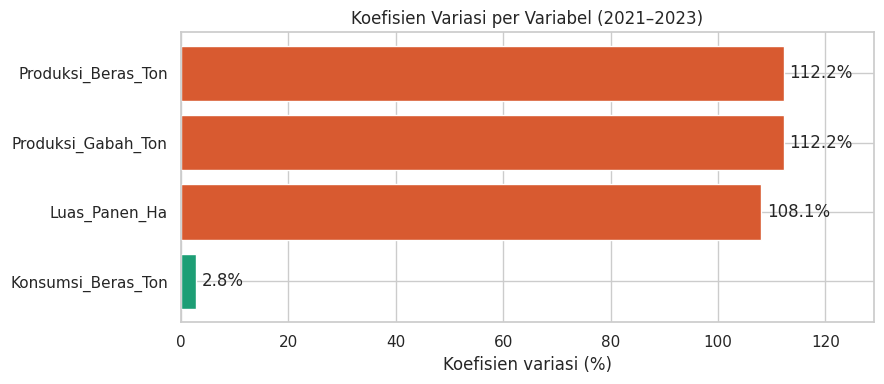

In [ ]:
# Hilangkan label "0" di atas nama kolom
df.columns.name = None

kolom_analisis = ["Luas_Panen_Ha", "Produksi_Gabah_Ton", "Produksi_Beras_Ton",
                  "Konsumsi_Beras_Ton", "Surplus_Defisit_Ton"]

# Tabel statistik deskriptif
desk = df[kolom_analisis].describe().T
desk["median"] = df[kolom_analisis].median()
desk["CV_%"] = desk["std"] / desk["mean"] * 100          # koefisien variasi
desk["skewness"] = df[kolom_analisis].skew()             # kemencengan distribusi
desk = desk[["count", "mean", "median", "std", "min", "max", "CV_%", "skewness"]].round(2)
print("Statistik deskriptif (36 bulan, 2021–2023):")
display(desk)

# Jumlah bulan surplus dan defisit per tahun
print("\nJumlah bulan surplus/defisit per tahun:")
display(pd.crosstab(df["Tahun"], df["Status"]))

# Grafik koefisien variasi
cv = desk["CV_%"].drop("Surplus_Defisit_Ton").sort_values()
plt.figure(figsize=(9, 4))
bars = plt.barh(cv.index, cv.values, color=["#1D9E75" if v < 20 else "#D85A30" for v in cv.values])
plt.bar_label(bars, fmt="%.1f%%", padding=4)
plt.title("Koefisien Variasi per Variabel (2021–2023)")
plt.xlabel("Koefisien variasi (%)")
plt.xlim(0, cv.max() * 1.15)
plt.tight_layout()
plt.show()

# Plot deret waktu

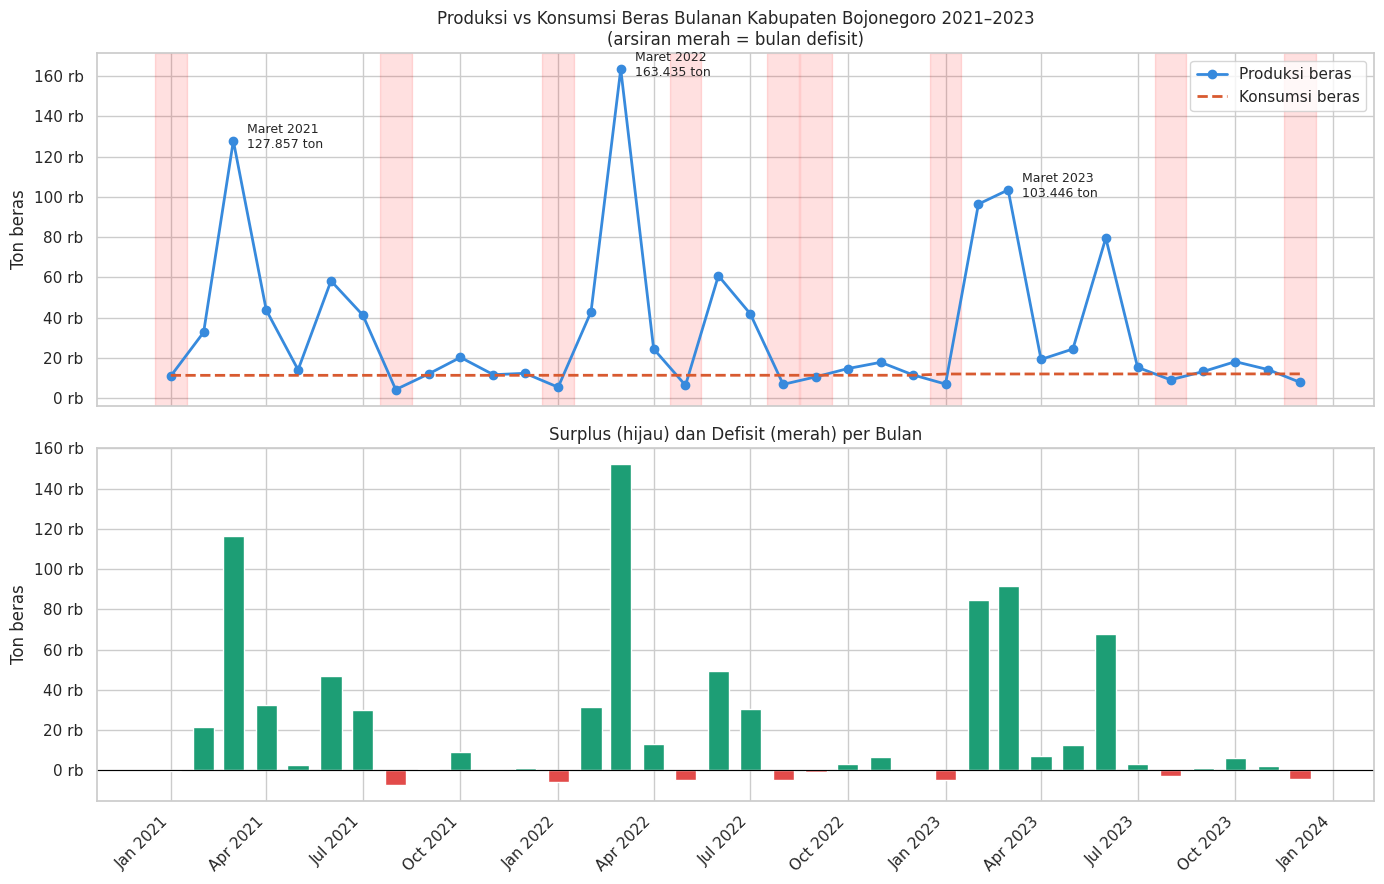

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Panel 1: Produksi beras vs konsumsi
ax1.plot(df["Periode"], df["Produksi_Beras_Ton"], marker="o", color="#378ADD",
         linewidth=2, label="Produksi beras")
ax1.plot(df["Periode"], df["Konsumsi_Beras_Ton"], color="#D85A30",
         linewidth=2, linestyle="--", label="Konsumsi beras")

# Arsir bulan defisit
for p in df.loc[df["Status"] == "Defisit", "Periode"]:
    ax1.axvspan(p - pd.Timedelta(days=15), p + pd.Timedelta(days=15), color="red", alpha=0.12)

# Tandai puncak produksi tiap tahun
for th, grup in df.groupby("Tahun"):
    puncak = grup.loc[grup["Produksi_Beras_Ton"].idxmax()]
    ax1.annotate(f"{puncak['Bulan']} {th}\n{puncak['Produksi_Beras_Ton']:,.0f} ton".replace(",", "."),
                 xy=(puncak["Periode"], puncak["Produksi_Beras_Ton"]),
                 xytext=(10, -5), textcoords="offset points", fontsize=9)

ax1.set_title("Produksi vs Konsumsi Beras Bulanan Kabupaten Bojonegoro 2021–2023\n(arsiran merah = bulan defisit)")
ax1.set_ylabel("Ton beras")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))
ax1.legend()

# Panel 2: Surplus/defisit per bulan
warna = np.where(df["Surplus_Defisit_Ton"] > 0, "#1D9E75", "#E24B4A")
ax2.bar(df["Periode"], df["Surplus_Defisit_Ton"], width=20, color=warna)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_title("Surplus (hijau) dan Defisit (merah) per Bulan")
ax2.set_ylabel("Ton beras")
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))

import matplotlib.dates as mdates
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.show()

# Boxplot per bulan (pola musiman)

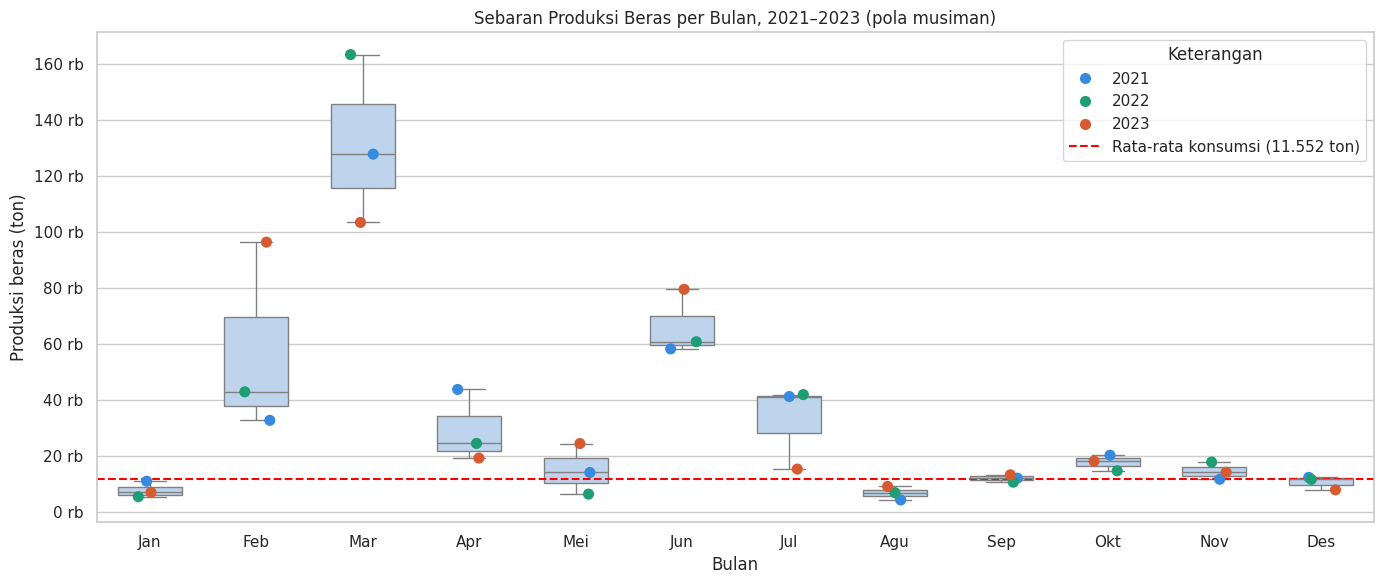

Rata-rata per bulan (3 tahun):


,Rata2_Produksi,Rata2_Konsumsi,Rata2_Surplus,Kali_Defisit
Jan,7766.0,11536.0,-3771.0,3
Feb,57330.0,11539.0,45791.0,0
Mar,131579.0,11543.0,120037.0,0
Apr,29132.0,11545.0,17587.0,0
Mei,14930.0,11548.0,3382.0,1
Jun,66188.0,11551.0,54636.0,0
Jul,32800.0,11554.0,21246.0,0
Agu,6708.0,11557.0,-4849.0,3
Sep,11946.0,11560.0,386.0,1
Okt,17674.0,11563.0,6111.0,0


In [ ]:
singkat = ["Jan","Feb","Mar","Apr","Mei","Jun","Jul","Agu","Sep","Okt","Nov","Des"]
df["Bulan_Singkat"] = df["Bulan_No"].map(lambda x: singkat[x-1])

fig, ax = plt.subplots(figsize=(14, 6))

# Boxplot produksi beras per bulan
sns.boxplot(data=df, x="Bulan_Singkat", y="Produksi_Beras_Ton", order=singkat,
            color="#B5D4F4", width=0.6, showfliers=False, ax=ax)

# Titik data asli per tahun di atas boxplot
sns.stripplot(data=df, x="Bulan_Singkat", y="Produksi_Beras_Ton", order=singkat,
              hue="Tahun", palette=["#378ADD", "#1D9E75", "#D85A30"],
              size=8, jitter=0.15, ax=ax)

# Garis rata-rata konsumsi sebagai pembanding
ax.axhline(df["Konsumsi_Beras_Ton"].mean(), color="red", linestyle="--", linewidth=1.5,
           label=f"Rata-rata konsumsi ({df['Konsumsi_Beras_Ton'].mean():,.0f} ton)".replace(",", "."))

ax.set_title("Sebaran Produksi Beras per Bulan, 2021–2023 (pola musiman)")
ax.set_xlabel("Bulan")
ax.set_ylabel("Produksi beras (ton)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))
ax.legend(title="Keterangan")
plt.tight_layout()
plt.show()

# Tabel ringkas rata-rata per bulan
musiman = (df.groupby("Bulan_No")
             .agg(Rata2_Produksi=("Produksi_Beras_Ton", "mean"),
                  Rata2_Konsumsi=("Konsumsi_Beras_Ton", "mean"),
                  Rata2_Surplus=("Surplus_Defisit_Ton", "mean"),
                  Kali_Defisit=("Status", lambda s: (s == "Defisit").sum()))
             .round(0))
musiman.index = singkat
print("Rata-rata per bulan (3 tahun):")
display(musiman)

# Perbandingan antar tahun

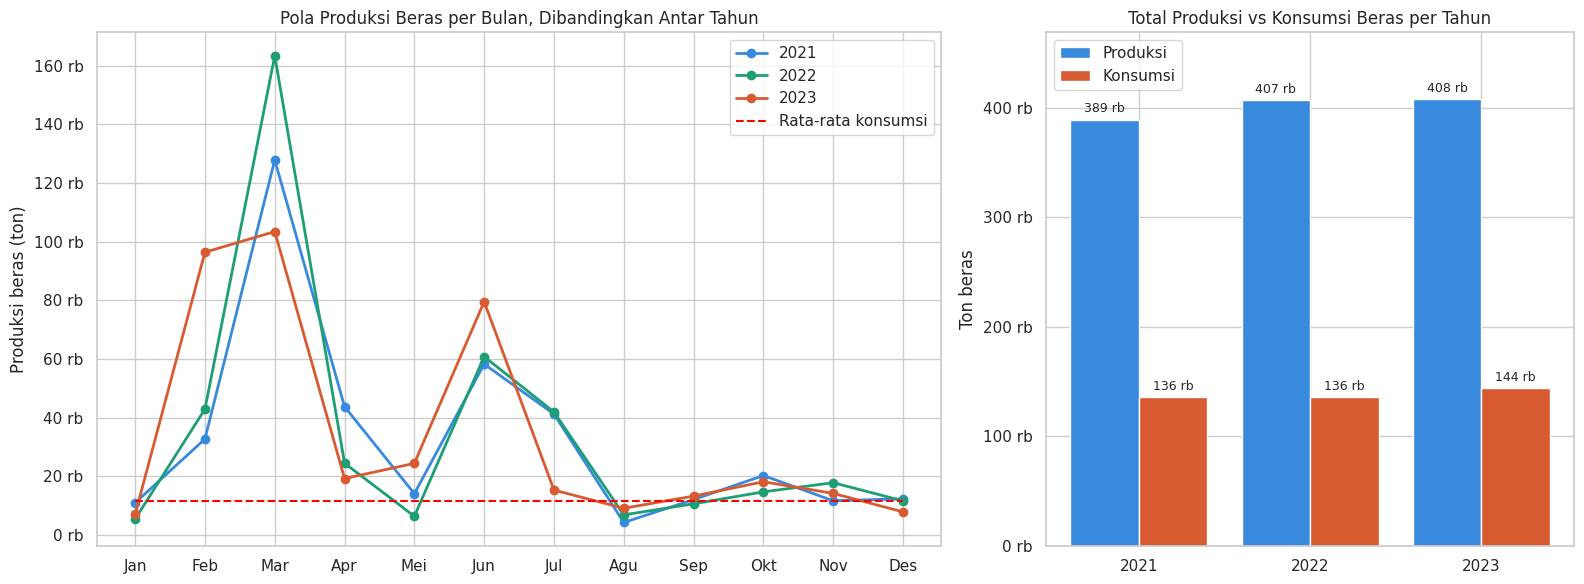

Ringkasan per tahun:


,Luas_Panen_Ha,Produksi_Beras_Ton,Konsumsi_Beras_Ton,Surplus_Ton,Bulan_Defisit,Rasio_Swasembada_%
Tahun,,,,,,
2021,134609,389182,135752,253430,2,286.7
2022,133666,406670,136140,270530,4,298.7
2023,132712,407637,143997,263640,3,283.1



Perubahan dibanding tahun sebelumnya (%):


,Luas_Panen_Ha_Perubahan_%,Produksi_Beras_Ton_Perubahan_%,Konsumsi_Beras_Ton_Perubahan_%,Surplus_Ton_Perubahan_%
Tahun,,,,
2022,-0.70,4.49,0.29,6.75
2023,-0.71,0.24,5.77,-2.55


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.6, 1]})
warna_tahun = {2021: "#378ADD", 2022: "#1D9E75", 2023: "#D85A30"}

# (a) Seasonal plot: satu garis per tahun
for th, grup in df.groupby("Tahun"):
    ax1.plot(grup["Bulan_Singkat"], grup["Produksi_Beras_Ton"], marker="o",
             linewidth=2, color=warna_tahun[th], label=str(th))
ax1.plot(singkat, df.groupby("Bulan_No")["Konsumsi_Beras_Ton"].mean(),
         color="red", linestyle="--", label="Rata-rata konsumsi")
ax1.set_title("Pola Produksi Beras per Bulan, Dibandingkan Antar Tahun")
ax1.set_ylabel("Produksi beras (ton)")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))
ax1.legend()

# (b) Total tahunan produksi vs konsumsi
tahunan = df.groupby("Tahun")[["Produksi_Beras_Ton", "Konsumsi_Beras_Ton", "Surplus_Defisit_Ton"]].sum()
x = np.arange(len(tahunan))
b1 = ax2.bar(x - 0.2, tahunan["Produksi_Beras_Ton"], 0.4, color="#378ADD", label="Produksi")
b2 = ax2.bar(x + 0.2, tahunan["Konsumsi_Beras_Ton"], 0.4, color="#D85A30", label="Konsumsi")
for bars in (b1, b2):
    ax2.bar_label(bars, labels=[f"{v/1000:.0f} rb" for v in bars.datavalues], padding=3, fontsize=9)
ax2.set_xticks(x, tahunan.index.astype(str))
ax2.set_title("Total Produksi vs Konsumsi Beras per Tahun")
ax2.set_ylabel("Ton beras")
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))
ax2.set_ylim(0, tahunan["Produksi_Beras_Ton"].max() * 1.15)
ax2.legend()
plt.tight_layout()
plt.show()

# Tabel perubahan antar tahun
ringkas = df.groupby("Tahun").agg(
    Luas_Panen_Ha=("Luas_Panen_Ha", "sum"),
    Produksi_Beras_Ton=("Produksi_Beras_Ton", "sum"),
    Konsumsi_Beras_Ton=("Konsumsi_Beras_Ton", "sum"),
    Surplus_Ton=("Surplus_Defisit_Ton", "sum"),
    Bulan_Defisit=("Status", lambda s: (s == "Defisit").sum()))
ringkas["Rasio_Swasembada_%"] = (ringkas["Produksi_Beras_Ton"] / ringkas["Konsumsi_Beras_Ton"] * 100).round(1)
perubahan = (ringkas[["Luas_Panen_Ha", "Produksi_Beras_Ton", "Konsumsi_Beras_Ton", "Surplus_Ton"]]
             .pct_change() * 100).round(2).add_suffix("_Perubahan_%")
print("Ringkasan per tahun:")
display(ringkas)
print("\nPerubahan dibanding tahun sebelumnya (%):")
display(perubahan.dropna())

# Histogram distribusi produksi

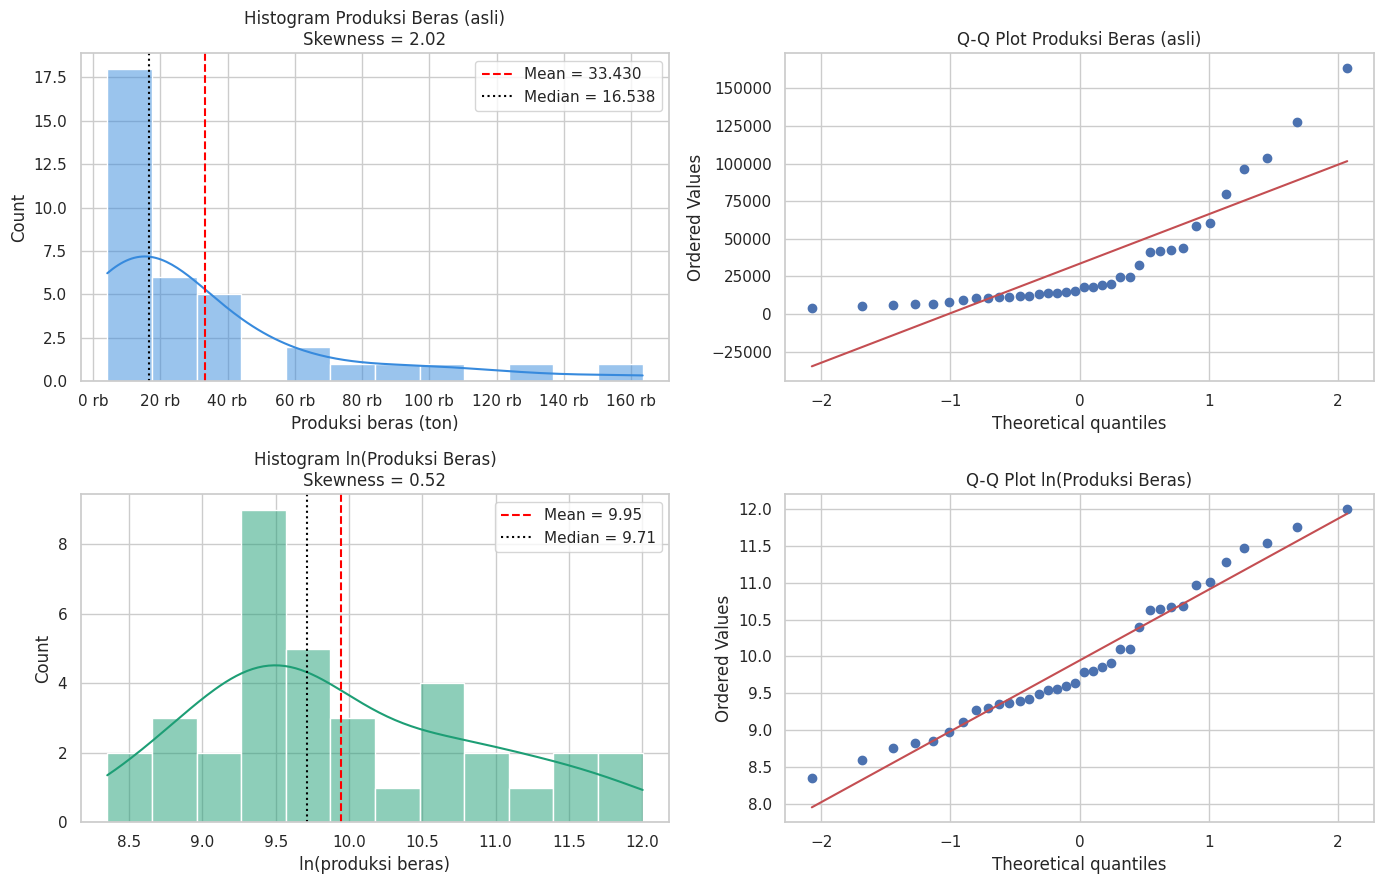

Shapiro-Wilk Asli: W = 0.7239, p-value = 0.0000 -> tidak normal
Shapiro-Wilk Log : W = 0.9550, p-value = 0.1498 -> normal


In [ ]:
from scipy import stats

prod = df["Produksi_Beras_Ton"]
log_prod = np.log(prod)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Baris 1: data asli
sns.histplot(prod, bins=12, kde=True, color="#378ADD", ax=axes[0, 0])
axes[0, 0].axvline(prod.mean(), color="red", linestyle="--", label=f"Mean = {prod.mean():,.0f}".replace(",", "."))
axes[0, 0].axvline(prod.median(), color="black", linestyle=":", label=f"Median = {prod.median():,.0f}".replace(",", "."))
axes[0, 0].set_title(f"Histogram Produksi Beras (asli)\nSkewness = {prod.skew():.2f}")
axes[0, 0].set_xlabel("Produksi beras (ton)")
axes[0, 0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))
axes[0, 0].legend()

stats.probplot(prod, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Q-Q Plot Produksi Beras (asli)")

# Baris 2: setelah log
sns.histplot(log_prod, bins=12, kde=True, color="#1D9E75", ax=axes[1, 0])
axes[1, 0].axvline(log_prod.mean(), color="red", linestyle="--", label=f"Mean = {log_prod.mean():.2f}")
axes[1, 0].axvline(log_prod.median(), color="black", linestyle=":", label=f"Median = {log_prod.median():.2f}")
axes[1, 0].set_title(f"Histogram ln(Produksi Beras)\nSkewness = {log_prod.skew():.2f}")
axes[1, 0].set_xlabel("ln(produksi beras)")
axes[1, 0].legend()

stats.probplot(log_prod, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q Plot ln(Produksi Beras)")

plt.tight_layout()
plt.show()

# Uji normalitas Shapiro-Wilk sebagai pelengkap
for nama, data in [("Asli", prod), ("Log", log_prod)]:
    stat, p = stats.shapiro(data)
    print(f"Shapiro-Wilk {nama:4s}: W = {stat:.4f}, p-value = {p:.4f} ->",
          "normal" if p > 0.05 else "tidak normal")

# Scatter plot luas panen vs produksi

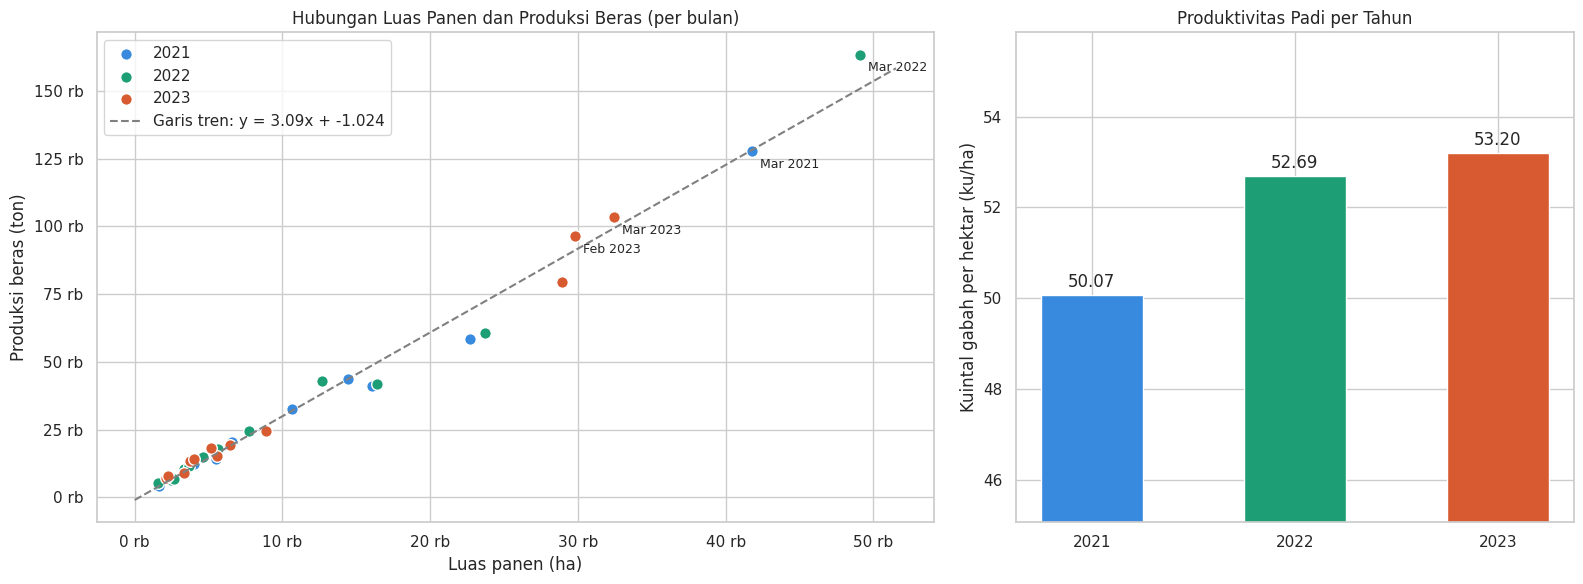

Korelasi Pearson  : r = 0.9925, p-value = 1.246e-32
Korelasi Spearman : r = 0.9910, p-value = 2.821e-31

Produktivitas (ku/ha):
Tahun
2021    50.07
2022    52.69
2023    53.20
dtype: float64


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.5, 1]})

# (a) Scatter luas panen vs produksi beras, warna per tahun
for th, grup in df.groupby("Tahun"):
    ax1.scatter(grup["Luas_Panen_Ha"], grup["Produksi_Beras_Ton"], s=70,
                color=warna_tahun[th], label=str(th), edgecolor="white")

# Garis regresi sederhana sebagai panduan visual
koef = np.polyfit(df["Luas_Panen_Ha"], df["Produksi_Beras_Ton"], 1)
x_garis = np.linspace(0, df["Luas_Panen_Ha"].max() * 1.05, 100)
ax1.plot(x_garis, np.polyval(koef, x_garis), color="gray", linestyle="--",
         label=f"Garis tren: y = {koef[0]:.2f}x + {koef[1]:,.0f}".replace(",", "."))

# Label titik-titik puncak
for _, r in df.nlargest(4, "Produksi_Beras_Ton").iterrows():
    ax1.annotate(f"{r['Bulan_Singkat']} {r['Tahun']}", (r["Luas_Panen_Ha"], r["Produksi_Beras_Ton"]),
                 xytext=(6, -12), textcoords="offset points", fontsize=9)

ax1.set_title("Hubungan Luas Panen dan Produksi Beras (per bulan)")
ax1.set_xlabel("Luas panen (ha)")
ax1.set_ylabel("Produksi beras (ton)")
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))
ax1.legend()

# (b) Produktivitas per tahun (kuintal gabah per hektar)
produktivitas = (df.groupby("Tahun")["Produksi_Gabah_Ton"].sum() * 10
                 / df.groupby("Tahun")["Luas_Panen_Ha"].sum())
bars = ax2.bar(produktivitas.index.astype(str), produktivitas.values,
               color=[warna_tahun[t] for t in produktivitas.index], width=0.5)
ax2.bar_label(bars, labels=[f"{v:.2f}" for v in produktivitas.values], padding=3)
ax2.set_title("Produktivitas Padi per Tahun")
ax2.set_ylabel("Kuintal gabah per hektar (ku/ha)")
ax2.set_ylim(produktivitas.min() * 0.9, produktivitas.max() * 1.05)
plt.tight_layout()
plt.show()

# Korelasi
r_pearson, p_pearson = stats.pearsonr(df["Luas_Panen_Ha"], df["Produksi_Beras_Ton"])
r_spearman, p_spearman = stats.spearmanr(df["Luas_Panen_Ha"], df["Produksi_Beras_Ton"])
print(f"Korelasi Pearson  : r = {r_pearson:.4f}, p-value = {p_pearson:.4g}")
print(f"Korelasi Spearman : r = {r_spearman:.4f}, p-value = {p_spearman:.4g}")
print("\nProduktivitas (ku/ha):")
print(produktivitas.round(2))

# Cek outlier

Q1 = 11.426 | Q3 = 42.151 | IQR = 30.726
Batas bawah = -34.662 | Batas atas = 88.240

Bulan yang terdeteksi outlier secara keseluruhan:


,Tahun,Bulan,Produksi_Beras_Ton,Luas_Panen_Ha
2,2021,Maret,127857,41759
14,2022,Maret,163435,49075
25,2023,Februari,96396,29810
26,2023,Maret,103446,32453



Selisih terbesar dibanding rata-rata bulan yang sama (3 tahun):


,Tahun,Bulan,Produksi_Beras_Ton,Selisih_dari_Rata2_Bulan_%
25,2023,Februari,96396,68.1
28,2023,Mei,24393,63.4
16,2022,Mei,6340,-57.5
30,2023,Juli,15280,-53.4
3,2021,April,43738,50.1
1,2021,Februari,32704,-43.0


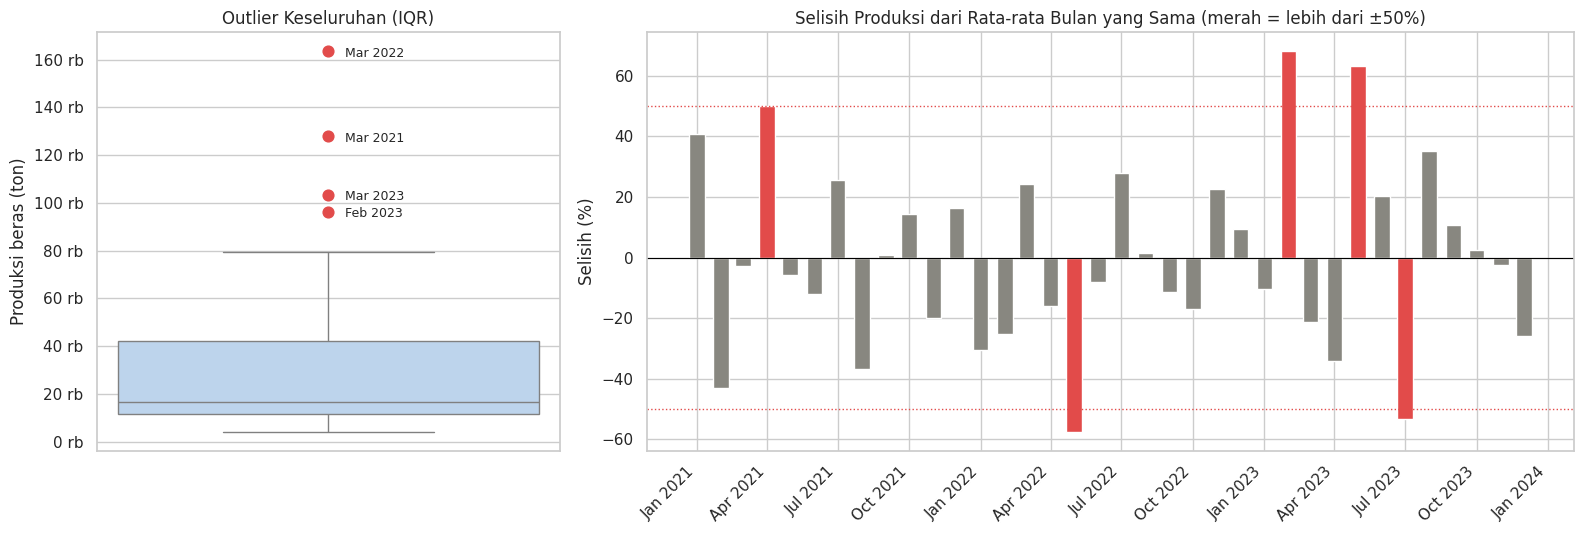

In [ ]:
# ===== 1. Outlier keseluruhan dengan metode IQR =====
Q1 = prod.quantile(0.25)
Q3 = prod.quantile(0.75)
IQR = Q3 - Q1
batas_atas = Q3 + 1.5 * IQR
batas_bawah = Q1 - 1.5 * IQR
df["Outlier_IQR"] = (prod > batas_atas) | (prod < batas_bawah)

print(f"Q1 = {Q1:,.0f} | Q3 = {Q3:,.0f} | IQR = {IQR:,.0f}".replace(",", "."))
print(f"Batas bawah = {batas_bawah:,.0f} | Batas atas = {batas_atas:,.0f}".replace(",", "."))
print("\nBulan yang terdeteksi outlier secara keseluruhan:")
display(df.loc[df["Outlier_IQR"], ["Tahun", "Bulan", "Produksi_Beras_Ton", "Luas_Panen_Ha"]])

# ===== 2. Outlier relatif terhadap bulan yang sama =====
rata_bulan = df.groupby("Bulan_No")["Produksi_Beras_Ton"].transform("mean")
df["Selisih_dari_Rata2_Bulan_%"] = ((prod - rata_bulan) / rata_bulan * 100).round(1)

print("\nSelisih terbesar dibanding rata-rata bulan yang sama (3 tahun):")
display(df.reindex(df["Selisih_dari_Rata2_Bulan_%"].abs().sort_values(ascending=False).index)
          [["Tahun", "Bulan", "Produksi_Beras_Ton", "Selisih_dari_Rata2_Bulan_%"]].head(6))

# ===== Visualisasi =====
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 2]})

# (a) Boxplot keseluruhan
sns.boxplot(y=prod, color="#B5D4F4", width=0.4, ax=ax1)
outlier = df[df["Outlier_IQR"]]
ax1.scatter([0] * len(outlier), outlier["Produksi_Beras_Ton"], color="#E24B4A", s=60, zorder=3)
for _, r in outlier.iterrows():
    ax1.annotate(f"{r['Bulan_Singkat']} {r['Tahun']}", (0, r["Produksi_Beras_Ton"]),
                 xytext=(12, -4), textcoords="offset points", fontsize=9)
ax1.set_title("Outlier Keseluruhan (IQR)")
ax1.set_ylabel("Produksi beras (ton)")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))

# (b) Selisih dari rata-rata bulan yang sama
warna_sel = ["#E24B4A" if abs(v) > 50 else "#888780" for v in df["Selisih_dari_Rata2_Bulan_%"]]
ax2.bar(df["Periode"], df["Selisih_dari_Rata2_Bulan_%"], width=20, color=warna_sel)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.axhline(50, color="#E24B4A", linestyle=":", linewidth=1)
ax2.axhline(-50, color="#E24B4A", linestyle=":", linewidth=1)
ax2.set_title("Selisih Produksi dari Rata-rata Bulan yang Sama (merah = lebih dari ±50%)")
ax2.set_ylabel("Selisih (%)")
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Membuat variabel trend dan dummy bulan

Variabel dummy: ['D_Feb', 'D_Mar', 'D_Apr', 'D_Mei', 'D_Jun', 'D_Jul', 'D_Agu', 'D_Sep', 'D_Okt', 'D_Nov', 'D_Des']
Ukuran data regresi: (36, 17)


,Periode,Tahun,Bulan,t,Produksi_Beras_Ton,ln_Produksi,D_Feb,D_Mar,D_Apr,D_Mei,D_Jun,D_Jul,D_Agu,D_Sep,D_Okt,D_Nov,D_Des
0,2021-01-01,2021,Januari,1,10924,9.298717,0,0,0,0,0,0,0,0,0,0,0
1,2021-02-01,2021,Februari,2,32704,10.395253,1,0,0,0,0,0,0,0,0,0,0
2,2021-03-01,2021,Maret,3,127857,11.758668,0,1,0,0,0,0,0,0,0,0,0
3,2021-04-01,2021,April,4,43738,10.685973,0,0,1,0,0,0,0,0,0,0,0
4,2021-05-01,2021,Mei,5,14057,9.550876,0,0,0,1,0,0,0,0,0,0,0
5,2021-06-01,2021,Juni,6,58240,10.972328,0,0,0,0,1,0,0,0,0,0,0
6,2021-07-01,2021,Juli,7,41215,10.626558,0,0,0,0,0,1,0,0,0,0,0
7,2021-08-01,2021,Agustus,8,4231,8.350194,0,0,0,0,0,0,1,0,0,0,0
8,2021-09-01,2021,September,9,12030,9.395159,0,0,0,0,0,0,0,1,0,0,0
9,2021-10-01,2021,Oktober,10,20242,9.915515,0,0,0,0,0,0,0,0,1,0,0


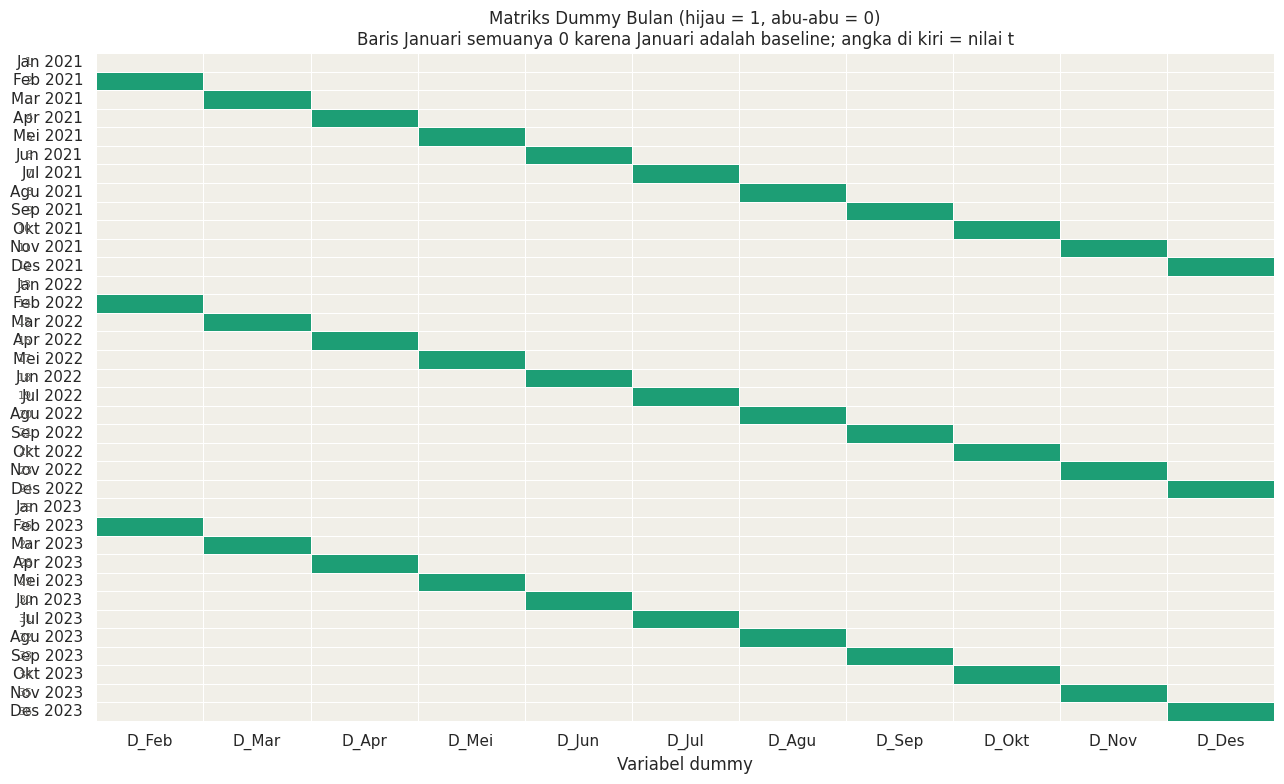

In [ ]:
# Variabel trend waktu
df["t"] = np.arange(1, len(df) + 1)

# Variabel respons dalam bentuk log
df["ln_Produksi"] = np.log(df["Produksi_Beras_Ton"])

# Dummy bulan (Januari sebagai baseline, jadi drop_first=True)
dummy = pd.get_dummies(pd.Categorical(df["Bulan_Singkat"], categories=singkat, ordered=True),
                       prefix="D", drop_first=True).astype(int)
dummy.index = df.index
nama_dummy = list(dummy.columns)

# Gabungkan jadi data siap regresi
data_reg = pd.concat([df[["Periode", "Tahun", "Bulan", "t", "Produksi_Beras_Ton", "ln_Produksi"]], dummy], axis=1)

print("Variabel dummy:", nama_dummy)
print("Ukuran data regresi:", data_reg.shape)
display(data_reg.head(14))

# Visualisasi matriks desain (t dan dummy) supaya terlihat strukturnya
fig, ax = plt.subplots(figsize=(13, 8))
matriks = data_reg[nama_dummy].copy()
sns.heatmap(matriks, cmap=["#F1EFE8", "#1D9E75"], cbar=False, linewidths=0.5, linecolor="white",
            yticklabels=[f"{b[:3]} {th}" for b, th in zip(data_reg["Bulan"], data_reg["Tahun"])], ax=ax)
for i, tval in enumerate(data_reg["t"]):
    ax.text(-0.6, i + 0.5, str(tval), ha="right", va="center", fontsize=8, color="#5F5E5A")
ax.set_title("Matriks Dummy Bulan (hijau = 1, abu-abu = 0)\nBaris Januari semuanya 0 karena Januari adalah baseline; angka di kiri = nilai t")
ax.set_xlabel("Variabel dummy")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

# Model regresi linear (Model 1)

                            OLS Regression Results                            
Dep. Variable:     Produksi_Beras_Ton   R-squared:                       0.889
Model:                            OLS   Adj. R-squared:                  0.832
Method:                 Least Squares   F-statistic:                     15.40
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           3.10e-08
Time:                        14:57:45   Log-Likelihood:                -390.13
No. Observations:                  36   AIC:                             806.3
Df Residuals:                      23   BIC:                             826.8
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       6932.6285   9520.249      0.728      0.4

,Koefisien,Std_Error,t_hitung,p_value,Signifikan_5%
const,6932.6,9520.2,0.728,0.4738,Tidak
t,64.1,261.9,0.245,0.8089,Tidak
D_Feb,49500.3,12575.7,3.936,0.0007,Ya
D_Mar,123685.5,12583.9,9.829,0.0000,Ya
D_Apr,21174.4,12597.5,1.681,0.1063,Tidak
D_Mei,6908.0,12616.6,0.548,0.5893,Tidak
D_Jun,58101.6,12641.0,4.596,0.0001,Ya
D_Jul,24649.9,12670.8,1.945,0.0640,Tidak
D_Agu,-1506.2,12706.0,-0.119,0.9067,Tidak
D_Sep,3667.7,12746.4,0.288,0.7761,Tidak


R-squared          : 0.8893
Adjusted R-squared : 0.8316
Uji F              : F = 15.399, p-value = 3.1e-08


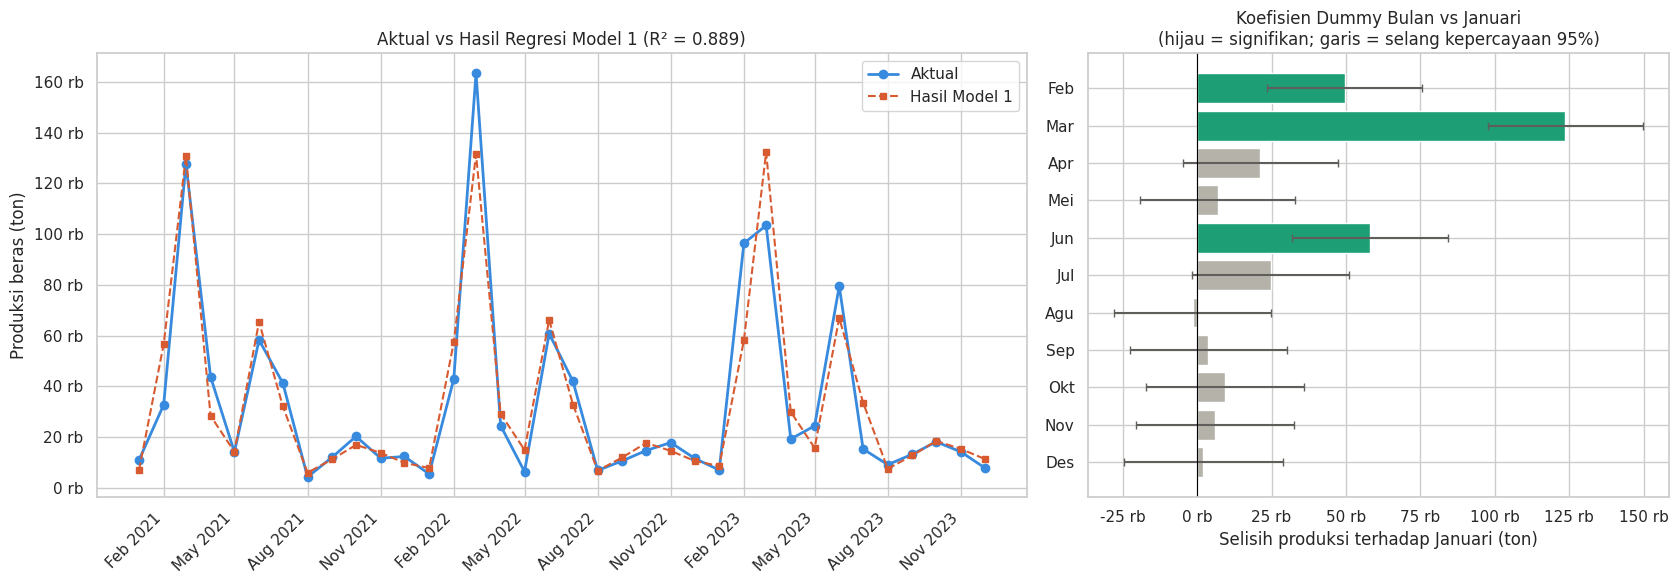

In [ ]:
import statsmodels.api as sm

# Variabel X: t + 11 dummy bulan, ditambah konstanta (intercept)
X = sm.add_constant(data_reg[["t"] + nama_dummy])
y1 = data_reg["Produksi_Beras_Ton"]

model1 = sm.OLS(y1, X).fit()
print(model1.summary())

# Tabel koefisien yang lebih mudah dibaca
koef1 = pd.DataFrame({
    "Koefisien": model1.params.round(1),
    "Std_Error": model1.bse.round(1),
    "t_hitung": model1.tvalues.round(3),
    "p_value": model1.pvalues.round(4),
})
koef1["Signifikan_5%"] = np.where(koef1["p_value"] < 0.05, "Ya", "Tidak")
print("\nRingkasan koefisien Model 1:")
display(koef1)

print(f"R-squared          : {model1.rsquared:.4f}")
print(f"Adjusted R-squared : {model1.rsquared_adj:.4f}")
print(f"Uji F              : F = {model1.fvalue:.3f}, p-value = {model1.f_pvalue:.3g}")

# ===== Visualisasi =====
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.6, 1]})

# (a) Aktual vs hasil model
ax1.plot(data_reg["Periode"], y1, marker="o", color="#378ADD", linewidth=2, label="Aktual")
ax1.plot(data_reg["Periode"], model1.fittedvalues, marker="s", markersize=4,
         color="#D85A30", linestyle="--", linewidth=1.5, label="Hasil Model 1")
ax1.set_title(f"Aktual vs Hasil Regresi Model 1 (R² = {model1.rsquared:.3f})")
ax1.set_ylabel("Produksi beras (ton)")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")
ax1.legend()

# (b) Koefisien dummy bulan dengan selang kepercayaan 95%
ci = model1.conf_int().loc[nama_dummy]
nilai = model1.params[nama_dummy]
warna_k = ["#1D9E75" if p < 0.05 else "#B4B2A9" for p in model1.pvalues[nama_dummy]]
label_b = [d.replace("D_", "") for d in nama_dummy]
ax2.barh(label_b, nilai, color=warna_k,
         xerr=[nilai - ci[0], ci[1] - nilai], capsize=3, ecolor="#5F5E5A")
ax2.axvline(0, color="black", linewidth=0.8)
ax2.invert_yaxis()
ax2.set_title("Koefisien Dummy Bulan vs Januari\n(hijau = signifikan; garis = selang kepercayaan 95%)")
ax2.set_xlabel("Selisih produksi terhadap Januari (ton)")
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))
plt.tight_layout()
plt.show()

# Uji asumsi klasik (Model 1)

===== Uji asumsi klasik: Model 1 (Produksi Beras, ton) =====


/tmp/ipykernel_4024/2188212318.py:22: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_stat, bg_p, _, _ = acorr_breusch_godfrey(model, nlags=1)


,Asumsi,Uji,Statistik,p_value,Terpenuhi
0,Normalitas,Shapiro-Wilk,0.8998,0.0034,Tidak
1,Normalitas,Jarque-Bera,11.7594,0.0028,Tidak
2,Homoskedastisitas,Breusch-Pagan,22.9494,0.0282,Tidak
3,Non-autokorelasi,Durbin-Watson,2.6568,NaN,Tidak
4,Non-autokorelasi,Breusch-Godfrey (lag 1),3.9559,0.0467,Tidak


VIF maksimum = 1.930 -> tidak ada multikolinearitas


,0,1,2,3,4,5,6,7,8,9,10,11
Variabel,t,D_Feb,D_Mar,D_Apr,D_Mei,D_Jun,D_Jul,D_Agu,D_Sep,D_Okt,D_Nov,D_Des
VIF,1.124,1.834,1.837,1.84,1.846,1.853,1.862,1.872,1.884,1.898,1.913,1.93


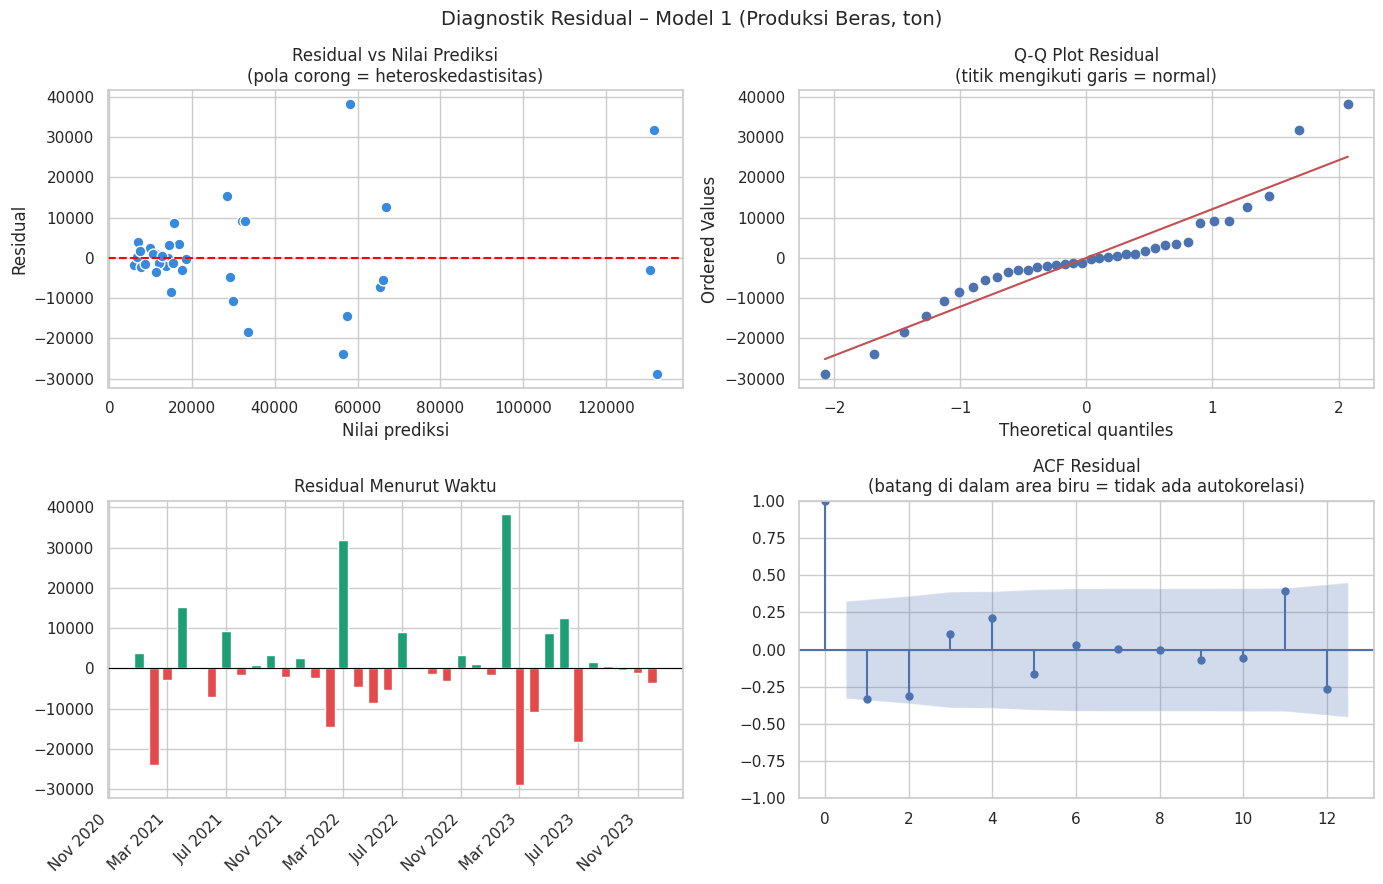

In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_breusch_godfrey
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.graphics.tsaplots import plot_acf

def uji_asumsi(model, nama_model):
    resid = model.resid
    hasil = []

    # 1. Normalitas
    sw_stat, sw_p = stats.shapiro(resid)
    jb_stat, jb_p, _, _ = jarque_bera(resid)
    hasil.append(["Normalitas", "Shapiro-Wilk", sw_stat, sw_p, sw_p > 0.05])
    hasil.append(["Normalitas", "Jarque-Bera", jb_stat, jb_p, jb_p > 0.05])

    # 2. Homoskedastisitas
    bp_stat, bp_p, _, _ = het_breuschpagan(resid, model.model.exog)
    hasil.append(["Homoskedastisitas", "Breusch-Pagan", bp_stat, bp_p, bp_p > 0.05])

    # 3. Autokorelasi
    dw = durbin_watson(resid)
    bg_stat, bg_p, _, _ = acorr_breusch_godfrey(model, nlags=1)
    hasil.append(["Non-autokorelasi", "Durbin-Watson", dw, np.nan, 1.5 < dw < 2.5])
    hasil.append(["Non-autokorelasi", "Breusch-Godfrey (lag 1)", bg_stat, bg_p, bg_p > 0.05])

    tabel = pd.DataFrame(hasil, columns=["Asumsi", "Uji", "Statistik", "p_value", "Terpenuhi"])
    tabel["Statistik"] = tabel["Statistik"].round(4)
    tabel["p_value"] = tabel["p_value"].round(4)
    tabel["Terpenuhi"] = tabel["Terpenuhi"].map({True: "Ya", False: "Tidak"})
    print(f"===== Uji asumsi klasik: {nama_model} =====")
    display(tabel)

    # 4. Multikolinearitas (VIF), tanpa konstanta
    exog = model.model.exog
    nama_var = model.model.exog_names
    vif = pd.DataFrame({
        "Variabel": nama_var[1:],
        "VIF": [variance_inflation_factor(exog, i) for i in range(1, exog.shape[1])]
    }).round(3)
    print(f"VIF maksimum = {vif['VIF'].max():.3f} ->",
          "tidak ada multikolinearitas" if vif["VIF"].max() < 10 else "ada multikolinearitas")
    display(vif.T)

    # ===== Grafik diagnostik =====
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))

    axes[0, 0].scatter(model.fittedvalues, resid, color="#378ADD", edgecolor="white", s=60)
    axes[0, 0].axhline(0, color="red", linestyle="--")
    axes[0, 0].set_title("Residual vs Nilai Prediksi\n(pola corong = heteroskedastisitas)")
    axes[0, 0].set_xlabel("Nilai prediksi")
    axes[0, 0].set_ylabel("Residual")

    stats.probplot(resid, dist="norm", plot=axes[0, 1])
    axes[0, 1].set_title("Q-Q Plot Residual\n(titik mengikuti garis = normal)")

    axes[1, 0].bar(data_reg["Periode"], resid, width=20,
                   color=np.where(resid > 0, "#1D9E75", "#E24B4A"))
    axes[1, 0].axhline(0, color="black", linewidth=0.8)
    axes[1, 0].set_title("Residual Menurut Waktu")
    axes[1, 0].xaxis.set_major_locator(mdates.MonthLocator(interval=4))
    axes[1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    plt.setp(axes[1, 0].get_xticklabels(), rotation=45, ha="right")

    plot_acf(resid, lags=12, ax=axes[1, 1])
    axes[1, 1].set_title("ACF Residual\n(batang di dalam area biru = tidak ada autokorelasi)")

    fig.suptitle(f"Diagnostik Residual – {nama_model}", fontsize=14)
    plt.tight_layout()
    plt.show()
    return tabel

asumsi_m1 = uji_asumsi(model1, "Model 1 (Produksi Beras, ton)")

# Model 2: regresi log dan uji asumsi

                            OLS Regression Results                            
Dep. Variable:            ln_Produksi   R-squared:                       0.886
Model:                            OLS   Adj. R-squared:                  0.827
Method:                 Least Squares   F-statistic:                     14.97
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           4.08e-08
Time:                        15:06:09   Log-Likelihood:                -9.5211
No. Observations:                  36   AIC:                             45.04
Df Residuals:                      23   BIC:                             65.63
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          8.9161      0.244     36.568      0.0

,Asumsi,Uji,Statistik,p_value,Terpenuhi
0,Normalitas,Shapiro-Wilk,0.9886,0.9666,Ya
1,Normalitas,Jarque-Bera,0.1284,0.9378,Ya
2,Homoskedastisitas,Breusch-Pagan,18.6195,0.0981,Ya
3,Non-autokorelasi,Durbin-Watson,2.4131,NaN,Ya
4,Non-autokorelasi,Breusch-Godfrey (lag 1),2.1052,0.1468,Ya


VIF maksimum = 1.930 -> tidak ada multikolinearitas


,0,1,2,3,4,5,6,7,8,9,10,11
Variabel,t,D_Feb,D_Mar,D_Apr,D_Mei,D_Jun,D_Jul,D_Agu,D_Sep,D_Okt,D_Nov,D_Des
VIF,1.124,1.834,1.837,1.84,1.846,1.853,1.862,1.872,1.884,1.898,1.913,1.93


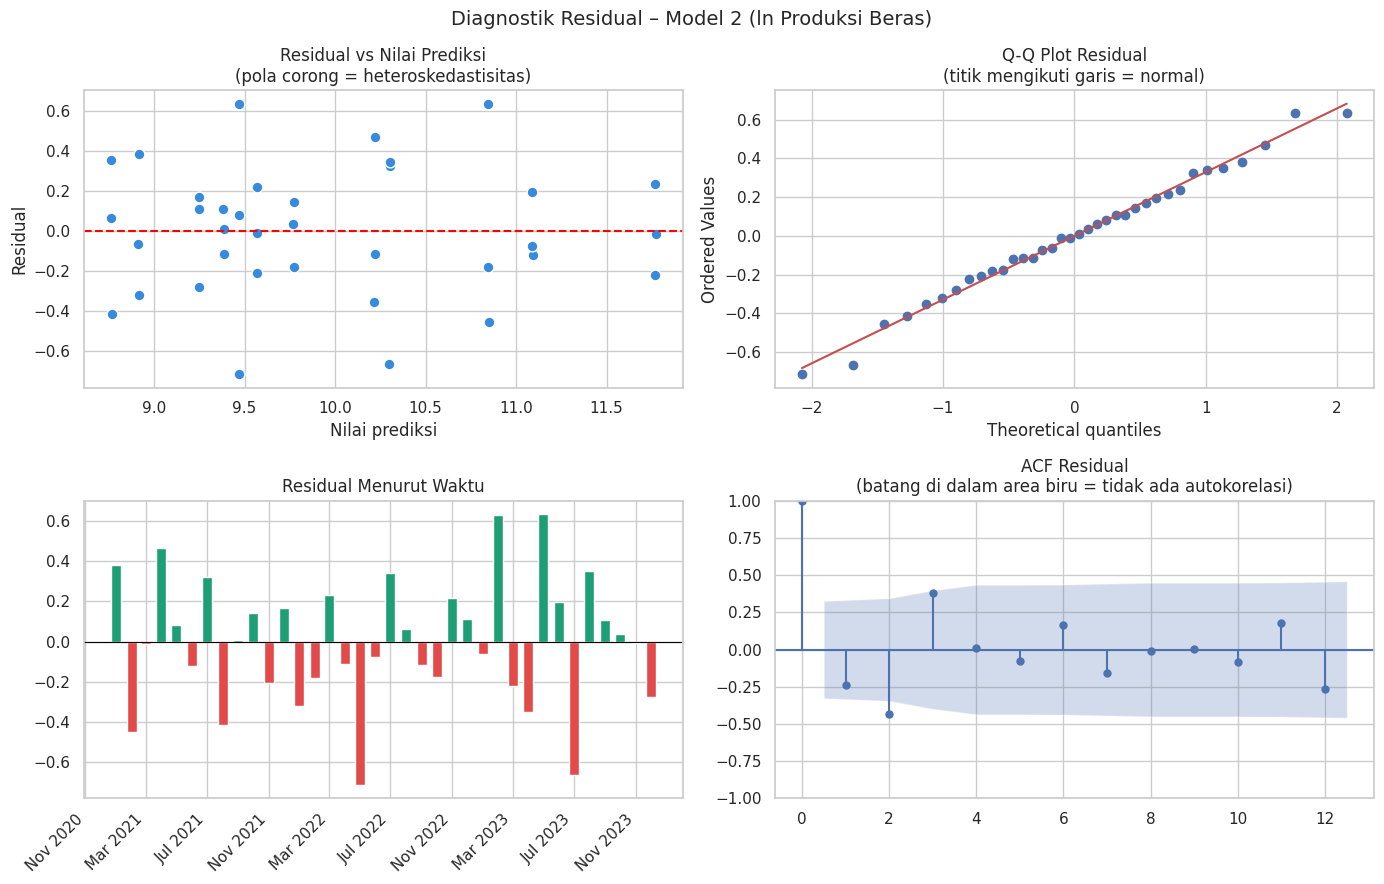


Koefisien Model 2 (untuk t: perubahan % per bulan; untuk dummy: % dibanding Januari):


,Koefisien,Perubahan_vs_Jan_%,p_value_OLS,p_value_HAC,Signifikan_HAC_5%
const,8.9161,NaN,0.0000,0.0000,Ya
t,-0.0001,-0.014,0.9834,0.9753,Tidak
D_Feb,1.9318,590.200,0.0000,0.0000,Ya
D_Mar,2.8559,1638.900,0.0000,0.0000,Ya
D_Apr,1.3040,268.400,0.0005,0.0000,Ya
D_Mei,0.5554,74.300,0.0990,0.1191,Tidak
D_Jun,2.1769,781.900,0.0000,0.0000,Ya
D_Jul,1.3879,300.600,0.0003,0.0000,Ya
D_Agu,-0.1497,-13.900,0.6497,0.5503,Tidak
D_Sep,0.4709,60.100,0.1627,0.0071,Ya



Perbandingan Model 1 vs Model 2:


,Model 1 (ton),Model 2 (log)
Uji,,
Shapiro-Wilk,Tidak,Ya
Jarque-Bera,Tidak,Ya
Breusch-Pagan,Tidak,Ya
Durbin-Watson,Tidak,Ya
Breusch-Godfrey (lag 1),Tidak,Ya
R-squared,0.8893,0.8865
Adjusted R-squared,0.8316,0.8273


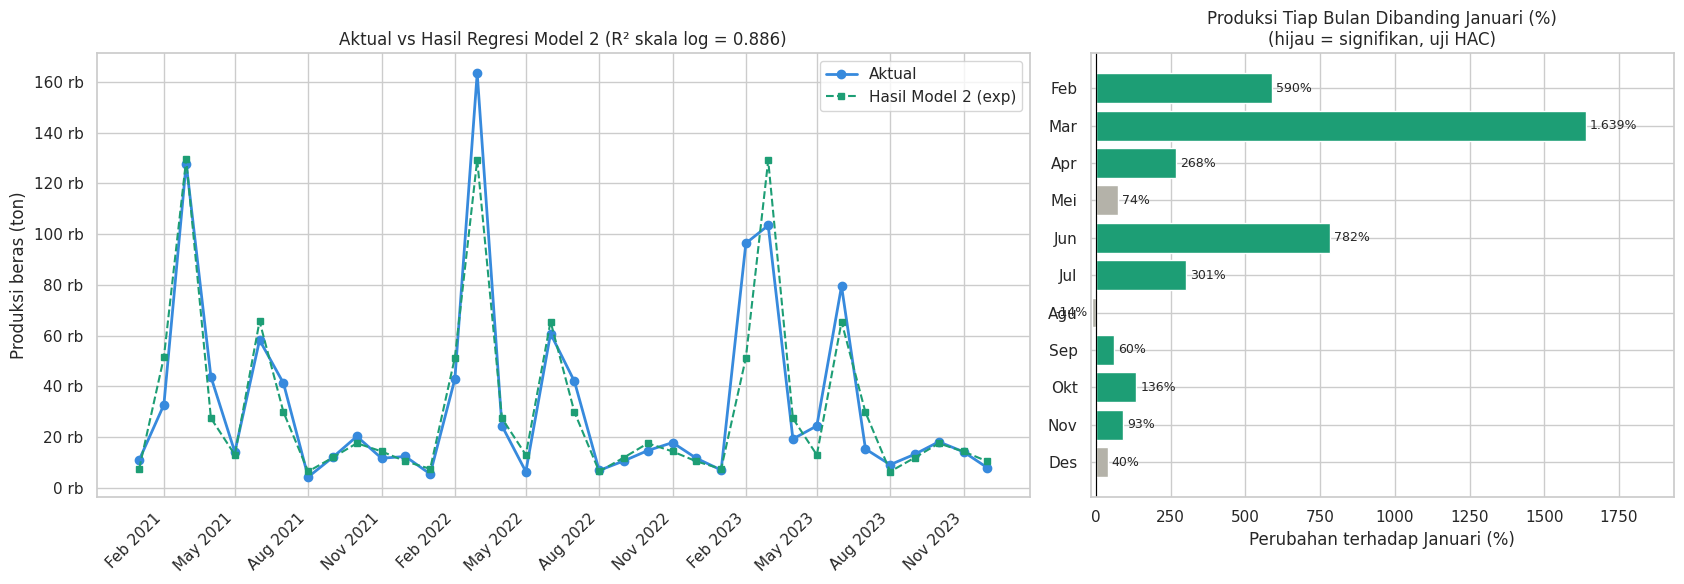

In [14]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# ===== Estimasi Model 2 =====
y2 = data_reg["ln_Produksi"]
model2 = sm.OLS(y2, X).fit()
print(model2.summary())

# Uji asumsi Model 2 (memakai fungsi dari Langkah 12)
asumsi_m2 = uji_asumsi(model2, "Model 2 (ln Produksi Beras)")

# ===== Model 2 dengan standard error HAC (Newey-West) =====
model2_hac = sm.OLS(y2, X).fit(cov_type="HAC", cov_kwds={"maxlags": 1})

koef2 = pd.DataFrame({
    "Koefisien": model2.params.round(4),
    "Perubahan_vs_Jan_%": ((np.exp(model2.params) - 1) * 100).round(1),
    "p_value_OLS": model2.pvalues.round(4),
    "p_value_HAC": model2_hac.pvalues.round(4),
})
koef2.loc[["const", "t"], "Perubahan_vs_Jan_%"] = np.nan   # tafsiran persen hanya untuk dummy
koef2.loc["t", "Perubahan_vs_Jan_%"] = round((np.exp(model2.params["t"]) - 1) * 100, 3)  # % per bulan
koef2["Signifikan_HAC_5%"] = np.where(koef2["p_value_HAC"] < 0.05, "Ya", "Tidak")
print("\nKoefisien Model 2 (untuk t: perubahan % per bulan; untuk dummy: % dibanding Januari):")
display(koef2)

# ===== Perbandingan Model 1 vs Model 2 =====
banding = pd.DataFrame({
    "Model 1 (ton)": asumsi_m1.set_index("Uji")["Terpenuhi"],
    "Model 2 (log)": asumsi_m2.set_index("Uji")["Terpenuhi"],
})
banding.loc["R-squared"] = [round(model1.rsquared, 4), round(model2.rsquared, 4)]
banding.loc["Adjusted R-squared"] = [round(model1.rsquared_adj, 4), round(model2.rsquared_adj, 4)]
print("\nPerbandingan Model 1 vs Model 2:")
display(banding)

# ===== Visualisasi =====
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.6, 1]})

# (a) Aktual vs hasil Model 2 (dikembalikan ke satuan ton dengan exp)
ax1.plot(data_reg["Periode"], y1, marker="o", color="#378ADD", linewidth=2, label="Aktual")
ax1.plot(data_reg["Periode"], np.exp(model2.fittedvalues), marker="s", markersize=4,
         color="#1D9E75", linestyle="--", linewidth=1.5, label="Hasil Model 2 (exp)")
ax1.set_title(f"Aktual vs Hasil Regresi Model 2 (R² skala log = {model2.rsquared:.3f})")
ax1.set_ylabel("Produksi beras (ton)")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")
ax1.legend()

# (b) Efek musiman dalam persen dibanding Januari
persen = koef2.loc[nama_dummy, "Perubahan_vs_Jan_%"]
warna_p = ["#1D9E75" if p < 0.05 else "#B4B2A9" for p in koef2.loc[nama_dummy, "p_value_HAC"]]
bars = ax2.barh([d.replace("D_", "") for d in nama_dummy], persen, color=warna_p)
ax2.bar_label(bars, labels=[f"{v:,.0f}%".replace(",", ".") for v in persen], padding=3, fontsize=9)
ax2.axvline(0, color="black", linewidth=0.8)
ax2.invert_yaxis()
ax2.set_title("Produksi Tiap Bulan Dibanding Januari (%)\n(hijau = signifikan, uji HAC)")
ax2.set_xlabel("Perubahan terhadap Januari (%)")
ax2.set_xlim(min(0, persen.min()) * 1.2, persen.max() * 1.18)
plt.tight_layout()
plt.show()

# Proyeksi 2024 dan surplus/defisit

In [15]:
from scipy.stats import norm

# ===== 1. Data masa depan (2024): t = 37..48 + dummy bulan =====
masa_depan = pd.DataFrame({
    "Periode": pd.date_range("2024-01-01", periods=12, freq="MS"),
    "Tahun": 2024,
    "Bulan_No": range(1, 13),
    "t": range(37, 49),
})
masa_depan["Bulan_Singkat"] = [singkat[i - 1] for i in masa_depan["Bulan_No"]]
dummy_fd = pd.get_dummies(pd.Categorical(masa_depan["Bulan_Singkat"], categories=singkat, ordered=True),
                          prefix="D", drop_first=True).astype(int)
X_fd = sm.add_constant(pd.concat([masa_depan[["t"]], dummy_fd], axis=1), has_constant="add")
X_fd = X_fd[X.columns]   # pastikan urutan kolom sama dengan model

# ===== 2. Proyeksi produksi dari Model 2 =====
pred = model2.get_prediction(X_fd).summary_frame(alpha=0.05)
smearing = np.mean(np.exp(model2.resid))
print(f"Faktor koreksi smearing (Duan) = {smearing:.4f}")

masa_depan["Prediksi_Produksi"] = np.exp(pred["mean"]) * smearing
masa_depan["Batas_Bawah_95"] = np.exp(pred["obs_ci_lower"])
masa_depan["Batas_Atas_95"] = np.exp(pred["obs_ci_upper"])

# ===== 3. Proyeksi konsumsi dengan regresi trend =====
model_kons = sm.OLS(df["Konsumsi_Beras_Ton"], sm.add_constant(df["t"])).fit()
print(f"Model konsumsi: Konsumsi = {model_kons.params['const']:,.1f} + {model_kons.params['t']:.2f}·t"
      f" | R² = {model_kons.rsquared:.3f} | p-value t = {model_kons.pvalues['t']:.4g}")
masa_depan["Prediksi_Konsumsi"] = model_kons.predict(sm.add_constant(masa_depan["t"], has_constant="add"))

# ===== 4. Surplus/defisit dan peluang defisit =====
masa_depan["Prediksi_Surplus"] = masa_depan["Prediksi_Produksi"] - masa_depan["Prediksi_Konsumsi"]
masa_depan["Status"] = np.where(masa_depan["Prediksi_Surplus"] > 0, "Surplus", "Defisit")

sd_obs = np.sqrt(pred["mean_se"] ** 2 + model2.scale)          # simpangan baku prediksi (skala log)
masa_depan["Peluang_Defisit_%"] = (norm.cdf((np.log(masa_depan["Prediksi_Konsumsi"]) - pred["mean"]) / sd_obs) * 100).round(1)
masa_depan["Kategori"] = pd.cut(masa_depan["Peluang_Defisit_%"], bins=[-1, 20, 50, 101],
                                labels=["Aman", "Waspada", "Rawan"])

tabel_proyeksi = masa_depan[["Bulan_Singkat", "Prediksi_Produksi", "Batas_Bawah_95", "Batas_Atas_95",
                             "Prediksi_Konsumsi", "Prediksi_Surplus", "Status",
                             "Peluang_Defisit_%", "Kategori"]].round(0)
print("\nProyeksi neraca beras Kabupaten Bojonegoro tahun 2024:")
display(tabel_proyeksi)
print(f"Total proyeksi produksi 2024 : {masa_depan['Prediksi_Produksi'].sum():,.0f} ton".replace(",", "."))
print(f"Total proyeksi konsumsi 2024 : {masa_depan['Prediksi_Konsumsi'].sum():,.0f} ton".replace(",", "."))
print(f"Total proyeksi surplus 2024  : {masa_depan['Prediksi_Surplus'].sum():,.0f} ton".replace(",", "."))

Faktor koreksi smearing (Duan) = 1.0502
Model konsumsi: Konsumsi = 11,075.4 + 25.79·t | R² = 0.715 | p-value t = 8.54e-11

Proyeksi neraca beras Kabupaten Bojonegoro tahun 2024:


,Bulan_Singkat,Prediksi_Produksi,Batas_Bawah_95,Batas_Atas_95,Prediksi_Konsumsi,Prediksi_Surplus,Status,Peluang_Defisit_%,Kategori
0,Jan,7785.0,2729.0,20133.0,12030.0,-4245.0,Defisit,84.0,Rawan
1,Feb,53721.0,18833.0,138933.0,12055.0,41666.0,Surplus,0.0,Aman
2,Mar,135332.0,47444.0,349994.0,12081.0,123251.0,Surplus,0.0,Aman
3,Apr,28666.0,10050.0,74135.0,12107.0,16559.0,Surplus,5.0,Aman
4,Mei,13559.0,4753.0,35066.0,12133.0,1426.0,Surplus,45.0,Waspada
5,Jun,68603.0,24051.0,177420.0,12158.0,56444.0,Surplus,0.0,Aman
6,Jul,31162.0,10925.0,80590.0,12184.0,18978.0,Surplus,3.0,Aman
7,Agu,6696.0,2347.0,17316.0,12210.0,-5514.0,Defisit,91.0,Rawan
8,Sep,12452.0,4365.0,32203.0,12236.0,216.0,Surplus,53.0,Rawan
9,Okt,18337.0,6429.0,47423.0,12262.0,6076.0,Surplus,23.0,Waspada


Total proyeksi produksi 2024 : 402.157 ton
Total proyeksi konsumsi 2024 : 146.056 ton
Total proyeksi surplus 2024  : 256.101 ton


# Visualisasi hasil proyeksi

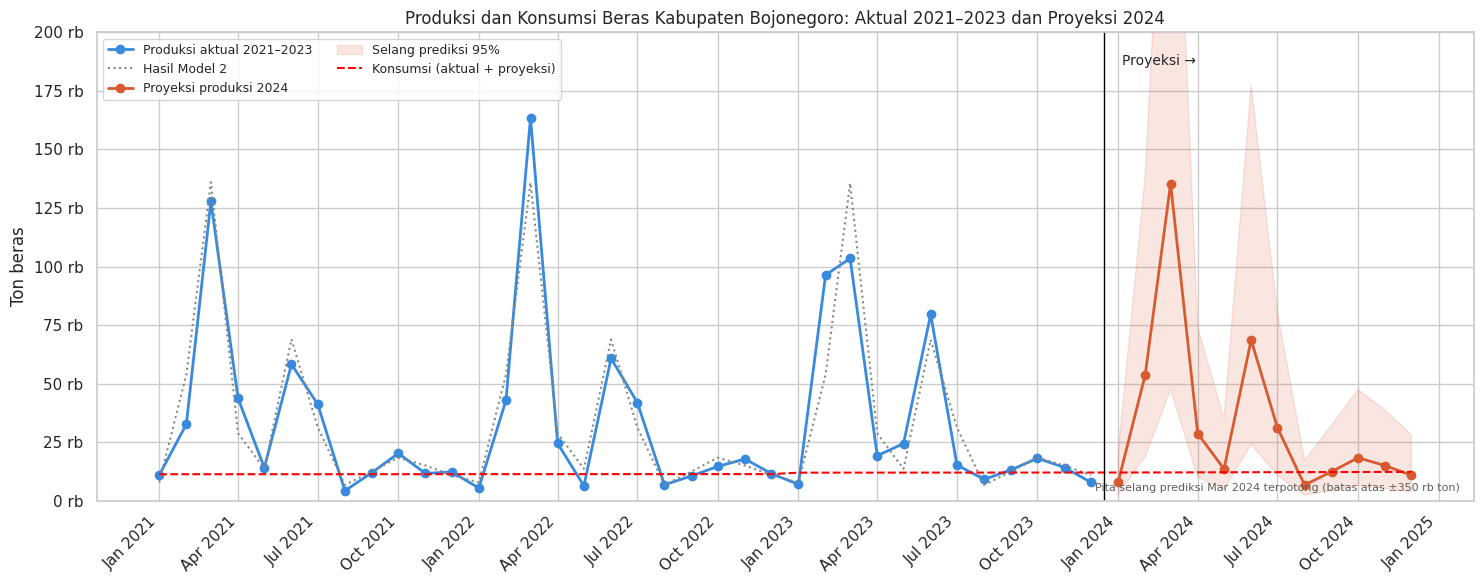

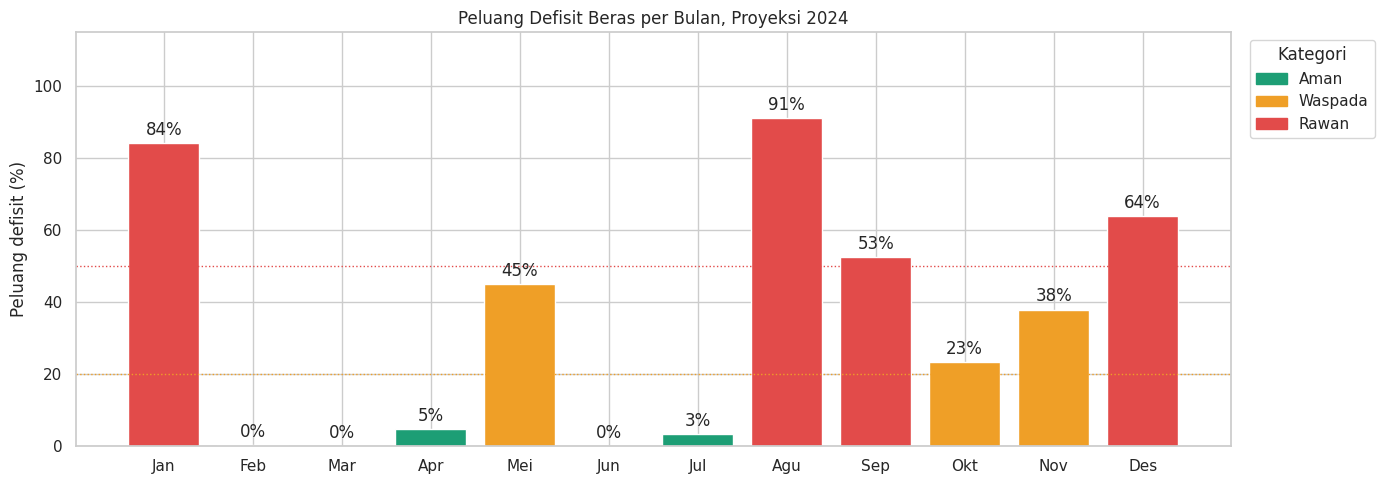

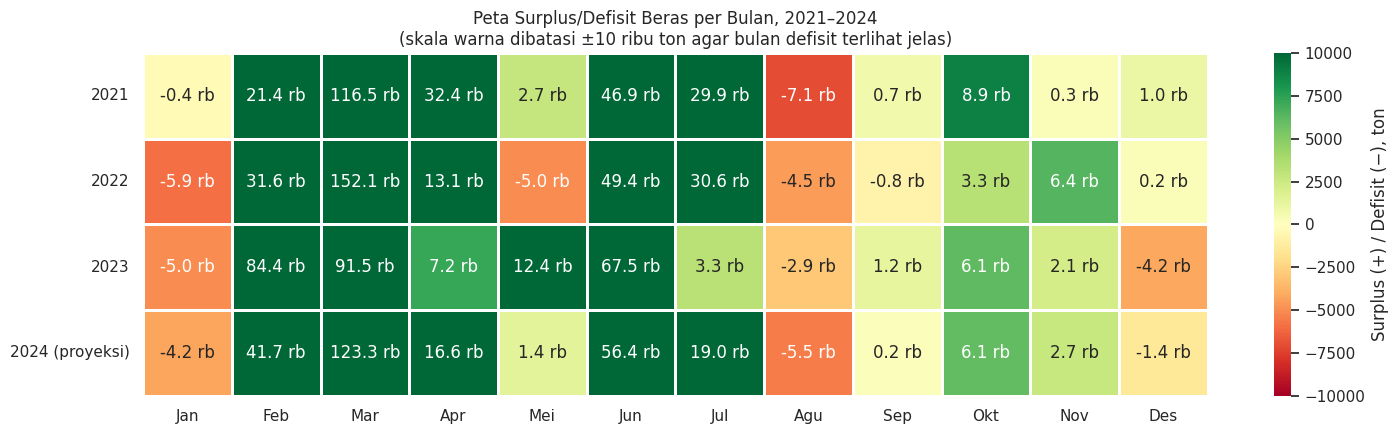

In [17]:
import matplotlib.patches as mpatches

warna_kat = {"Aman": "#1D9E75", "Waspada": "#EF9F27", "Rawan": "#E24B4A"}

# ===== Grafik 1: Garis waktu 2021–2024 =====
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(data_reg["Periode"], data_reg["Produksi_Beras_Ton"], marker="o", color="#378ADD",
        linewidth=2, label="Produksi aktual 2021–2023")
ax.plot(data_reg["Periode"], np.exp(model2.fittedvalues) * smearing, color="#888780",
        linestyle=":", linewidth=1.5, label="Hasil Model 2")
ax.plot(masa_depan["Periode"], masa_depan["Prediksi_Produksi"], marker="o", color="#D85A30",
        linewidth=2, label="Proyeksi produksi 2024")
ax.fill_between(masa_depan["Periode"], masa_depan["Batas_Bawah_95"], masa_depan["Batas_Atas_95"],
                color="#D85A30", alpha=0.15, label="Selang prediksi 95%")
semua_periode = pd.concat([df["Periode"], masa_depan["Periode"]])
semua_kons = pd.concat([df["Konsumsi_Beras_Ton"], masa_depan["Prediksi_Konsumsi"]])
ax.plot(semua_periode, semua_kons, color="red", linestyle="--", linewidth=1.5,
        label="Konsumsi (aktual + proyeksi)")

# Batas sumbu-Y diatur dulu, baru teks ditempatkan
ax.set_ylim(0, 200000)
ax.axvline(pd.Timestamp("2023-12-16"), color="black", linewidth=1)
ax.text(pd.Timestamp("2024-01-05"), 0.93, "Proyeksi →", transform=ax.get_xaxis_transform(), fontsize=10)

batas_atas_maks = masa_depan["Batas_Atas_95"].max()
bulan_maks = masa_depan.loc[masa_depan["Batas_Atas_95"].idxmax(), "Bulan_Singkat"]
ax.text(0.99, 0.02,
        f"Pita selang prediksi {bulan_maks} 2024 terpotong (batas atas ±{batas_atas_maks/1000:.0f} rb ton)",
        transform=ax.transAxes, ha="right", fontsize=8, color="#5F5E5A")

ax.set_title("Produksi dan Konsumsi Beras Kabupaten Bojonegoro: Aktual 2021–2023 dan Proyeksi 2024")
ax.set_ylabel("Ton beras")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend(loc="upper left", ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

# ===== Grafik 2: Peluang defisit 2024 =====
fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(masa_depan["Bulan_Singkat"], masa_depan["Peluang_Defisit_%"],
              color=[warna_kat[k] for k in masa_depan["Kategori"]])
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in masa_depan["Peluang_Defisit_%"]], padding=3)
ax.axhline(50, color="#E24B4A", linestyle=":", linewidth=1)
ax.axhline(20, color="#EF9F27", linestyle=":", linewidth=1)
ax.set_ylim(0, 115)
ax.set_title("Peluang Defisit Beras per Bulan, Proyeksi 2024")
ax.set_ylabel("Peluang defisit (%)")
ax.legend(handles=[mpatches.Patch(color=c, label=k) for k, c in warna_kat.items()],
          title="Kategori", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

# ===== Grafik 3: Heatmap surplus/defisit 2021–2024 =====
hist = df.pivot(index="Tahun", columns="Bulan_No", values="Surplus_Defisit_Ton")
proy = masa_depan.set_index("Bulan_No")["Prediksi_Surplus"].rename(2024).to_frame().T
peta = pd.concat([hist, proy])
peta.columns = singkat
peta.index = ["2021", "2022", "2023", "2024 (proyeksi)"]

# Label angka di setiap kotak (map untuk pandas baru, applymap untuk pandas lama)
format_rb = lambda v: f"{v/1000:.1f} rb"
label_peta = peta.map(format_rb) if hasattr(peta, "map") else peta.applymap(format_rb)

fig, ax = plt.subplots(figsize=(15, 4.5))
sns.heatmap(peta, cmap="RdYlGn", center=0, vmin=-10000, vmax=10000,
            annot=label_peta, fmt="", linewidths=1, linecolor="white",
            cbar_kws={"label": "Surplus (+) / Defisit (−), ton"}, ax=ax)
ax.set_title("Peta Surplus/Defisit Beras per Bulan, 2021–2024\n"
             "(skala warna dibatasi ±10 ribu ton agar bulan defisit terlihat jelas)")
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

# Menyimpan hasil untuk dashboard dan laporan

In [18]:
import os, shutil
os.makedirs("hasil", exist_ok=True)

# 1. Data bersih (WAJIB, dipakai dashboard)
df[["Tahun", "Bulan", "Bulan_No", "Luas_Panen_Ha", "Produksi_Gabah_Ton",
    "Produksi_Beras_Ton", "Konsumsi_Beras_Ton", "Surplus_Defisit_Ton", "Status"]] \
  .to_csv("hasil/data_neraca_beras_bersih.csv", index=False)

# 2. Statistik deskriptif
desk.to_csv("hasil/statistik_deskriptif.csv")

# 3. Koefisien Model 2 (model final)
koef2.to_csv("hasil/koefisien_model2.csv")

# 4. Perbandingan uji asumsi Model 1 vs Model 2
banding.to_csv("hasil/perbandingan_asumsi.csv")

# 5. Proyeksi 2024
tabel_proyeksi.to_csv("hasil/proyeksi_2024.csv", index=False)

# 6. Ringkasan metrik model
pd.DataFrame({
    "Metrik": ["R2_Model1", "AdjR2_Model1", "R2_Model2", "AdjR2_Model2",
               "F_pvalue_Model2", "Smearing", "Konsumsi_intercept", "Konsumsi_slope"],
    "Nilai": [model1.rsquared, model1.rsquared_adj, model2.rsquared, model2.rsquared_adj,
              model2.f_pvalue, smearing, model_kons.params["const"], model_kons.params["t"]],
}).to_csv("hasil/ringkasan_model.csv", index=False)

# Gabungkan jadi satu file zip lalu download
shutil.make_archive("hasil_analisis_neraca_beras", "zip", "hasil")
print("File yang disimpan:", os.listdir("hasil"))
files.download("hasil_analisis_neraca_beras.zip")

File yang disimpan: ['statistik_deskriptif.csv', 'proyeksi_2024.csv', 'perbandingan_asumsi.csv', 'data_neraca_beras_bersih.csv', 'koefisien_model2.csv', 'ringkasan_model.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>